# Gabarito — Transformada de Fourier

Resolução das **Questões de verificação** e da seção **Pratique com Python** do notebook `intro-2-fourier-transform.ipynb`, mantendo o sinal e os procedimentos da versão traduzida para português brasileiro.

O objetivo é identificar as componentes de um sinal composto, interpretar sua FFT e compreender a diferença entre o sinal original e o sinal reconstruído pela IFFT **após a aplicação de uma janela de Tukey**.

## Questões de verificação

1. Observe o código abaixo do comentário "Definir três ondas senoidais". Quais são as frequências das três ondas senoidais?
2. Observe o gráfico do sinal no domínio do tempo. Você consegue identificar as frequências das componentes? (Dica: provavelmente não!)
3. Observe o gráfico do sinal no domínio da frequência. Você consegue identificar as frequências das componentes? Como?

In [1]:
# -- Importar as bibliotecas e recriar o sinal do notebook original
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 13})

# -- Frequência de amostragem e vetor de tempo: 5 segundos, 2000 amostras/s
fs = 2000  # Hz
time = np.arange(0, 5, 1/fs)

# -- Definir as três ondas senoidais
sine1 = np.sin(2*np.pi*190*time)
sine2 = np.sin(2*np.pi*220*time)
sine3 = np.sin(2*np.pi*310*time)

# -- Somar as componentes

data = sine1 + sine2 + sine3

print(f"Número de amostras: {len(data)}")
print(f"Duração da aquisição: {len(data)/fs:g} s")
print(f"Resolução nominal da FFT: {fs/len(data):.1f} Hz")

Número de amostras: 10000
Duração da aquisição: 5 s
Resolução nominal da FFT: 0.2 Hz


## Resposta 1 — Frequências das ondas senoidais

As três funções têm a forma $y(t)=\sin(2\pi f t)$. Comparando com o código, encontramos:

- `sine1`: **190 Hz**;
- `sine2`: **220 Hz**;
- `sine3`: **310 Hz**.

O sinal composto é a soma dessas três ondas:

$$x(t)=\sin(2\pi\,190t)+\sin(2\pi\,220t)+\sin(2\pi\,310t).$$

Cada uma possui amplitude igual a 1 antes da superposição.

## Resposta 2 — É possível identificar as frequências no domínio do tempo?

**Não facilmente.** O gráfico mostra a superposição das três senoides, formando uma oscilação complexa. Não é possível determinar diretamente, apenas por inspeção visual desse trecho, quais são as três frequências presentes.

Uma decomposição do sinal em componentes, por exemplo com a transformada de Fourier, permite identificá-las.

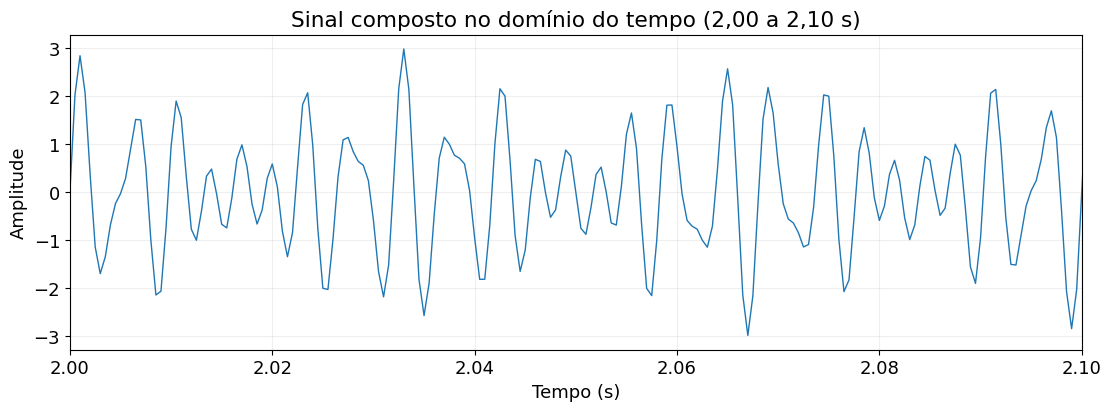

In [2]:
# -- Visualizar o mesmo trecho temporal do notebook original
plt.figure(layout="constrained")
plt.plot(time, data, lw=1)
plt.xlim(2, 2.1)
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.title('Sinal composto no domínio do tempo (2,00 a 2,10 s)')
plt.grid(alpha=0.2)
plt.show()

## Resposta 3 — Como identificar as frequências no domínio da frequência?

**Sim.** A FFT permite observar picos na magnitude do espectro próximos de **190 Hz, 220 Hz e 310 Hz**, correspondentes às três componentes do sinal.

No código abaixo, aplicamos a mesma janela de Tukey usada no notebook original e calculamos a transformada para dados reais (`np.fft.rfft`). O vetor `frequencies` indica a frequência correspondente a cada ponto de `data_freq`.

Para $N=10\,000$ amostras e $f_s=2000\,\mathrm{Hz}$, o espaçamento entre os pontos do espectro é $\delta f=f_s/N=0{,}2\,\mathrm{Hz}$.

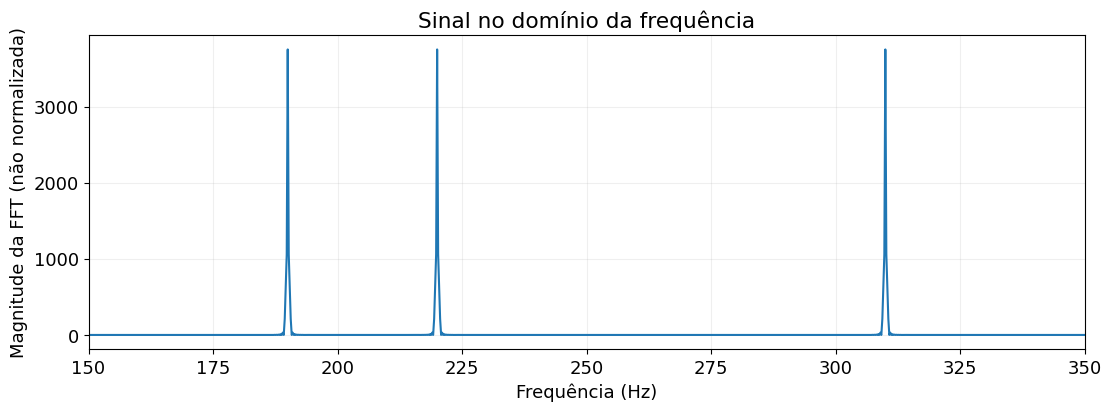

Componente: 190.0 Hz
Componente: 220.0 Hz
Componente: 310.0 Hz


In [3]:
# -- Aplicar a janela de Tukey e calcular a FFT
window = signal.windows.tukey(len(data))
data_window = window * data

data_freq = np.fft.rfft(data_window)
frequencies = np.fft.rfftfreq(len(data), d=1/fs)

plt.figure(layout="constrained")
plt.plot(frequencies, np.abs(data_freq))
plt.xlim(150, 350)
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude da FFT (não normalizada)')
plt.title('Sinal no domínio da frequência')
plt.grid(alpha=0.2)
plt.show()

# -- Conferir onde ficam as componentes conhecidas
for f in (190, 220, 310):
    k = np.argmin(np.abs(frequencies - f))
    print(f"Componente: {frequencies[k]:.1f} Hz")

## Pratique com Python

1. Adicione uma célula abaixo e tente representar graficamente uma onda senoidal com frequência de 30 Hz.
2. Represente no mesmo gráfico os dados originais e os dados após a IFFT, mas considere todo o intervalo de tempo. (Dica: remova o comando `plt.xlim(...)`.) Você percebe alguma diferença?

## Prática 1 — Representar uma senoide de 30 Hz

Criamos o sinal $y(t)=\sin(2\pi\,30t)$, usando a mesma frequência de amostragem do notebook: $f_s=2000\,\mathrm{Hz}$.

Para observar melhor os ciclos, mostramos apenas os primeiros $0{,}2\,\mathrm{s}$, que contêm **6 ciclos** da senoide de 30 Hz.

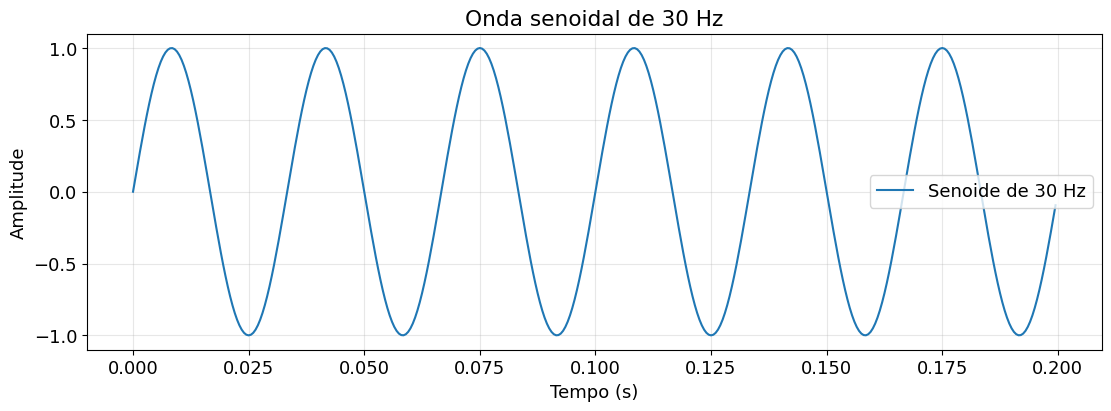

In [4]:
# -- Gerar e representar uma onda senoidal de 30 Hz
f = 30  # Hz
t30 = np.arange(0, 0.2, 1/fs)
sin30 = np.sin(2*np.pi*f*t30)

plt.figure(layout="constrained")
plt.plot(t30, sin30, label='Senoide de 30 Hz')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.title('Onda senoidal de 30 Hz')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Prática 2 — Comparar o sinal original e o sinal após a IFFT

Removemos o comando `plt.xlim(...)` para visualizar **todo o intervalo de 0 a 5 segundos**.

**O que se observa?** Os sinais se sobrepõem na parte central, mas **diferem nas extremidades**. A razão é que a FFT foi aplicada ao sinal *após a multiplicação pela janela de Tukey*, e não diretamente aos dados originais.

Assim, a transformada inversa reconstrói, salvo erros numéricos de arredondamento,

$$\mathrm{IFFT}\!\left[\mathrm{FFT}(w[n]x[n])\right]=w[n]x[n],$$

**não** o sinal original $x[n]$. A janela padrão de Tukey é igual a 1 na região central e tende a 0 nas extremidades. Por isso, a diferença fica mais evidente quando consideramos todo o intervalo temporal.

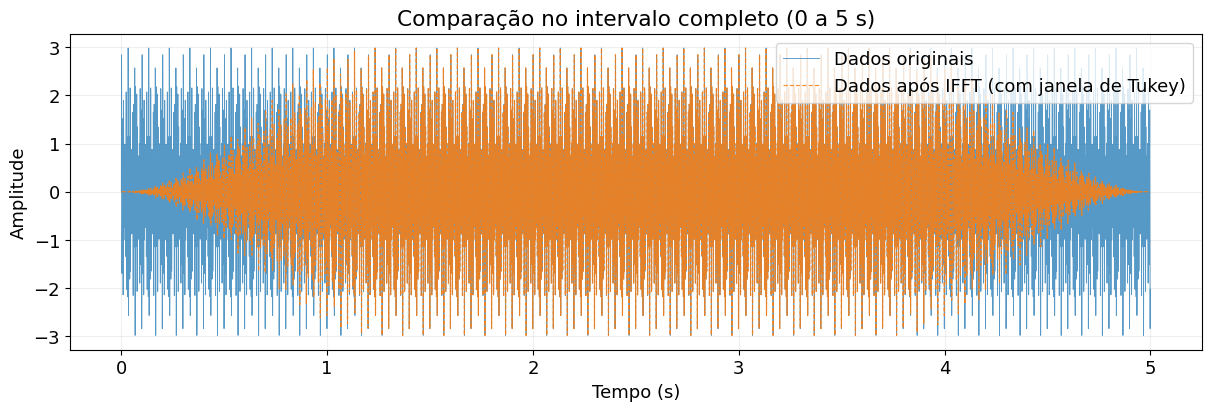

In [5]:
# -- Reconstruir os dados a partir da FFT do sinal com janela
# -- e comparar com os dados originais no intervalo completo

data_after_ifft = np.fft.irfft(data_freq, n=len(data))

plt.figure(figsize=(12, 4), layout="constrained")
plt.plot(time, data, lw=0.65, label='Dados originais', alpha=0.75)
plt.plot(time, data_after_ifft, '--', lw=0.85,
         label='Dados após IFFT (com janela de Tukey)', alpha=0.85)
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.title('Comparação no intervalo completo (0 a 5 s)')
plt.legend(loc='upper right')
plt.grid(alpha=0.2)
plt.show()

### Verificação — A IFFT reconstruiu corretamente o sinal com janela?

A diferença entre `data_after_ifft` e `window * data` deve ser praticamente zero, exceto por pequenos erros numéricos. Já a diferença em relação a `data` é real, pois a janela modifica o sinal.

O gráfico da janela de Tukey ajuda a entender por que as curvas coincidem no centro do intervalo e diferem perto das extremidades.

Maior diferença |IFFT - dados com janela|: 2.66e-15
Maior diferença |IFFT - dados originais|: 2.977


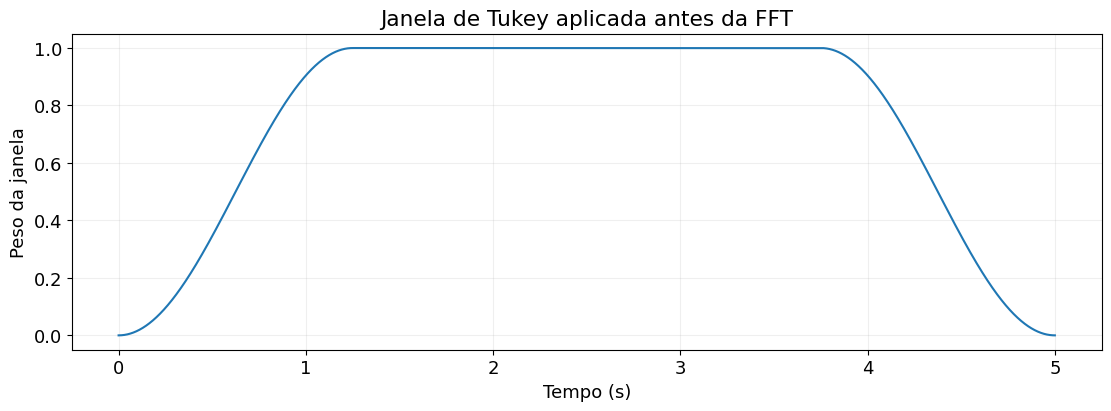

In [6]:
# -- Comparar quantitativamente as diferenças e visualizar a janela
print('Maior diferença |IFFT - dados com janela|:',
      f'{np.max(np.abs(data_after_ifft - data_window)):.2e}')
print('Maior diferença |IFFT - dados originais|:',
      f'{np.max(np.abs(data_after_ifft - data)):.3f}')

plt.figure(layout="constrained")
plt.plot(time, window)
plt.xlabel('Tempo (s)')
plt.ylabel('Peso da janela')
plt.title('Janela de Tukey aplicada antes da FFT')
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.2)
plt.show()

## Conclusão

A análise no domínio da frequência revela claramente as componentes de **190, 220 e 310 Hz**, difíceis de identificar diretamente na superposição temporal. Uma senoide isolada de **30 Hz** é gerada com `np.sin(2*np.pi*30*t)`.

A IFFT é capaz de recuperar o sinal que foi efetivamente transformado. Neste exercício, como a FFT recebeu `window * data`, a IFFT recupera **os dados multiplicados pela janela**, e não exatamente o sinal original. Para reconstruir o sinal original por FFT/IFFT sem essa modificação, seria necessário calcular a FFT diretamente de `data`.

*Gabarito complementar ao notebook original; manter os créditos e a licença do projeto de origem ao redistribuir os materiais.*